# 🐍 Python Foundations for AI
## Class 3 — Data Analysis & Feature Preparation

**Alexandra Oliveira** · AI Engineer  
**Catarina Santos** · AI Engineer

---

<div style="display:flex; align-items:center; gap:24px; margin-bottom:8px;">
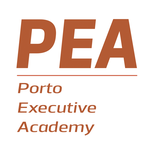
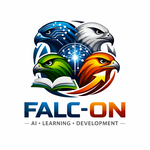
</div>

---

### 📋 What we'll cover today

| # | Topic |
|---|-------|
| 1 | What is a DataFrame? |
| 2 | Loading a file, and the first look |
| 3 | Selecting columns and filtering rows |
| 4 | Data quality — duplicates, messy text, missing values, personal data |
| 5 | Creating new columns — including a prompt for each ticket |
| 6 | Summarising — statistics and `groupby` |
| 7 | Saving your results |
| 8 | 🔗 Capstone — preparing tickets for an AI assistant |

### 🎯 Learning outcomes

By the end of this class you will be able to:

- Load a data file into Python and look around it
- Pick out the rows and columns you need
- Find and fix the usual problems in real data
- Prepare clean data, with no personal information, for an AI model

### 🤖 Why this class matters for AI

An AI model is only as useful as the **context you give it**. A support assistant that drafts replies needs to know about each ticket: the product, the problem, how urgent it is.

That context comes from **your data** — and real data is messy. Before any of it reaches a model, you need to:

- load it and understand its structure
- fix duplicates, inconsistent text and missing values
- remove personal information
- keep only what the model needs

Last class you built a **list of dictionaries** by hand, and saw it is the shape of a spreadsheet. Today a library called **pandas** reads a whole file into that shape for you.

### 📂 Today's file — `support_tickets.csv`

300 customer support tickets (and a few problems for you to find), with columns such as the product, the ticket type, its subject, status, priority and channel, the customer's age and their satisfaction rating from 1 to 5.

---
## 1. What is a DataFrame?

A **DataFrame** is a table: rows of data, with **named columns**. It is a spreadsheet you drive with code instead of the mouse.

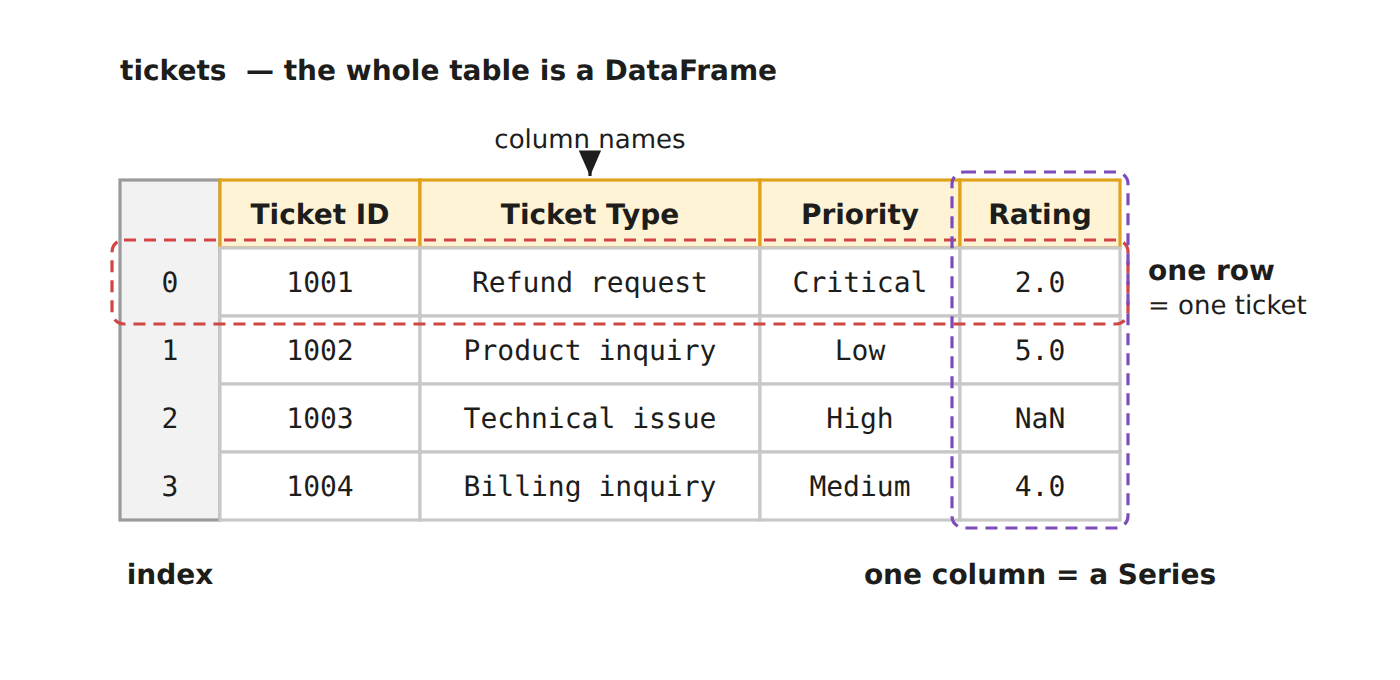

| Term | What it is |
|------|-----------|
| **DataFrame** | the whole table |
| **Series** | a single column, on its own |

---
## 2. Loading a File, and the First Look

### Bringing in pandas

pandas is a **library**, like `json` last class. Everyone brings it in the same way:

`import pandas as pd`

`as pd` gives it a short nickname, so you write `pd.read_csv(...)` instead of `pandas.read_csv(...)`.

In [ ]:
import pandas as pd
print("pandas is ready")

### Getting the file to Colab

Colab runs on Google's computers, not yours, so it **cannot see the files on your computer**. Put the file in your Colab files space first:

1. Click the **folder icon** 📁 in the left sidebar of Colab
2. Click the **upload icon** and choose `support_tickets.csv`
3. Wait until the file appears in the list

> ⚠️ Files uploaded this way are deleted when your Colab session ends. Upload the file again each time you come back.

Then `pd.read_csv()` reads it into a DataFrame. We keep the file name in a variable, `CSV_PATH`, so it is written in one place only.

In [ ]:
CSV_PATH = "support_tickets.csv"
tickets = pd.read_csv(CSV_PATH)

print(tickets.shape)             # (308, 12) - 308 rows, 12 columns

### The whole table

Write the name of the DataFrame on the last line of a cell, and Colab shows it as a table. With 308 rows it shows the first 5 and the last 5, with `...` in between.

> 💡 In a notebook, the **last line of a cell is shown by itself** — that is why `tickets` needs no `print()`.

In [ ]:
tickets

### `.head()` — the first rows

`.head()` shows only the first 5 rows — a quick look, without the rest. `.head(10)` shows 10.

In [ ]:
tickets.head()

### `.columns` — the column names

`list()` turns them into a plain list, easy to read.

In [ ]:
print(list(tickets.columns))

### `.info()` — types and missing values

For each column: how many values are **not** missing, and their type. It is the first health check to run on any new file.

In [ ]:
tickets.info()

---
## 3. Selecting Columns and Filtering Rows

### One column — a Series

Name the column in square brackets, like a dictionary key.

In [ ]:
print(tickets["Ticket Priority"].head())

### Several columns — a smaller DataFrame

> ⚠️ Several columns need **two** pairs of brackets: the inner pair is the **list** of names, the outer pair is the selection.

In [ ]:
tickets[["Ticket ID", "Ticket Priority", "Ticket Status"]].head()

### Filtering rows with a condition

`tickets["Ticket Priority"] == "Critical"` gives a column of `True`/`False`, one per row. Put it inside `tickets[...]` to keep only the `True` rows.

Read it from the inside out: *"the rows of tickets where the priority is Critical"*.

In [ ]:
critical = tickets[tickets["Ticket Priority"] == "Critical"]
print(len(critical))             # 101 critical tickets

### Combining conditions — `&` and `|`

| You want | Write |
|----------|-------|
| Both conditions | `tickets[(A) & (B)]` |
| Either condition | `tickets[(A) \| (B)]` |

> ⚠️ Two traps: use `&` and `|`, **not** `and` / `or`. And wrap each condition in **its own brackets**.

In [ ]:
# Critical AND not closed - the most urgent tickets
urgent = tickets[(tickets["Ticket Priority"] == "Critical") & (tickets["Ticket Status"] != "Closed")]
print(len(urgent))               # 71

In [ ]:
# Critical OR by phone - at least one of the two
critical_or_phone = tickets[(tickets["Ticket Priority"] == "Critical") | (tickets["Ticket Channel"] == "Phone")]
print(len(critical_or_phone))    # 144

### `.isin()` — the value is one of a list

`.isin([...])` saves a long chain of `==` joined by `|`.

In [ ]:
written = tickets[tickets["Ticket Channel"].isin(["Email", "Chat"])]
print(len(written))              # 149 tickets by email or chat

> 🤖 **AI Connection**
>
> Filtering is how you choose **what to send to a model**: only the open, critical tickets, for example. Sending the whole file would be slow, expensive, and confusing for the model.

---
## 4. Data Quality

Real files are never clean — and a model given messy data gives messy answers: **garbage in, garbage out**. Fix the data **before** you use it.

> ⚠️ The methods in this section give you back a **new** table and leave the original alone. To keep the result, assign it back: `tickets = tickets.drop_duplicates()`. Forgetting this is the most common pandas mistake.

### Missing values

A blank cell becomes `NaN` — *not a number*. `.isnull()` marks each one `True`, and `.sum()` counts them per column.

In [ ]:
print(tickets.isnull().sum())

### Duplicate rows — `.drop_duplicates()`

It removes rows identical to an earlier one. Compare `.shape` before and after.

In [ ]:
print("before:", tickets.shape)
tickets = tickets.drop_duplicates()
print("after: ", tickets.shape)     # 8 duplicated rows removed

### Messy text — `.str.lower()`

The same ticket type is written `Billing inquiry`, `billing inquiry` and `BILLING INQUIRY`. For Python those are three different values, which would split every count three ways.

`.str.lower()` puts a whole text column in lower case. `sorted(... .unique())` lists each different value once, in order.

In [ ]:
print(sorted(tickets["Ticket Type"].unique()))       # 8 spellings

tickets["Ticket Type"] = tickets["Ticket Type"].str.lower()
print(sorted(tickets["Ticket Type"].unique()))       # 5 ticket types

### Filling missing values — `.fillna()`

When a sensible stand-in exists, fill the gaps instead of losing the rows. A prompt should never contain `NaN`.

In [ ]:
tickets["Ticket Subject"] = tickets["Ticket Subject"].fillna("Unknown subject")
print(tickets["Ticket Subject"].isnull().sum())      # 0 - no gaps left

### Dropping rows with missing values — `.dropna()`

When a row is useless without a value, drop it. `subset=` says which column to check.

Only closed tickets have a satisfaction rating, so to study ratings we keep a separate table, `rated`. `tickets` keeps every ticket.

In [ ]:
rated = tickets.dropna(subset=["Customer Satisfaction Rating"])
print(len(rated))                # 95 tickets with a rating

### Removing columns — `.drop(columns=[...])`

The `Notes` column is completely empty, so it tells us nothing.

In [ ]:
tickets = tickets.drop(columns=["Notes"])

### 🤖 Removing personal data

Customer names and e-mail addresses must **never** be sent to an external AI model. Remove them before the data goes anywhere.

In [ ]:
tickets = tickets.drop(columns=["Customer Name", "Customer Email"])
print(list(tickets.columns))

---
## 5. Creating New Columns

Name the new column on the left, and give a recipe on the right. The recipe is applied to **every row at once** — no loop.

### A True/False column

`True` counts as 1, so `.sum()` counts the `True` values.

In [ ]:
tickets["urgent"] = (tickets["Ticket Priority"] == "Critical") & (tickets["Ticket Status"] != "Closed")
print(tickets["urgent"].sum())   # 68 urgent tickets

### A text column — one prompt per ticket

An AI model cannot read a table: it reads **text**. So, to ask a model about a ticket, we first turn that ticket's row into one sentence — its **prompt**. We build it from three columns. The first row, for example:

| Product Purchased | Ticket Type | Ticket Subject |
|-------------------|-------------|----------------|
| Autodesk AutoCAD | cancellation request | Product setup |

becomes the text `Product: Autodesk AutoCAD | Type: cancellation request | Subject: Product setup`.

The tool is `+`, which **glues texts together** — you met it in Class 1, where `"10" + "5"` gave `"105"`:

In [ ]:
print("Product: " + "Autodesk AutoCAD")      # Product: Autodesk AutoCAD

Used on columns, `+` glues **every row at once**. The result is a new column, `prompt`, with one sentence per ticket:

In [ ]:
tickets["prompt"] = (
    "Product: " + tickets["Product Purchased"]
    + " | Type: " + tickets["Ticket Type"]
    + " | Subject: " + tickets["Ticket Subject"]
)

The three columns, next to the prompt built from them:

In [ ]:
tickets[["Product Purchased", "Ticket Type", "Ticket Subject", "prompt"]].head(3)

A table cuts long text short. To read each prompt whole, loop over the column — a Series can be looped over like a list:

In [ ]:
for prompt in tickets["prompt"].head(3):
    print(prompt)

In the capstone, these prompts are exactly what we save for the AI assistant.

---
## 6. Summarising

### One number out of a column

| Method | Gives |
|--------|-------|
| `.mean()` | the average |
| `.min()` / `.max()` | the smallest / largest |
| `.sum()` | the total |
| `.round(1)` | rounded to 1 decimal |

In [ ]:
print(tickets["Customer Age"].mean().round(1))       # 43.5 - the average age
print(tickets["Customer Age"].min())                 # 18.0 - the youngest
print(tickets["Customer Age"].max())                 # 70.0 - the oldest

### What values are in a column

| Method | Gives |
|--------|-------|
| `.nunique()` | **how many** different values |
| `.value_counts()` | each value, and how often it appears |

In [ ]:
print(tickets["Product Purchased"].nunique())        # 42 different products
print(tickets["Ticket Status"].value_counts())

### `groupby` — the same statistic, per group

This replaces a dictionary, a loop and an `if`. Read it left to right:

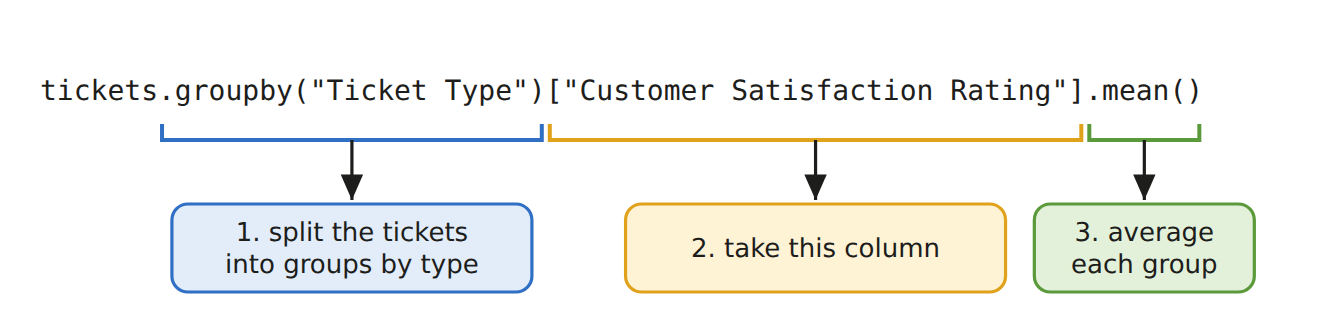

In [ ]:
by_type = tickets.groupby("Ticket Type")["Customer Satisfaction Rating"].mean().round(2)
print(by_type)

### Sorting the result — `.sort_values()`

`.sort_values()` puts the smallest first. Add `ascending=False` for the biggest first.

In [ ]:
print(by_type.sort_values(ascending=False))          # happiest first

> 🤖 **AI Connection**
>
> Customers with product questions are the happiest, those with **refund requests** the least happy. That tells you where an AI assistant would help most — data analysis *informs* AI design.

### Grouping by two columns

Give `groupby` a **list** of columns. Each line of the result is one **combination** — here, each ticket type with each priority:

In [ ]:
by_type_priority = tickets.groupby(["Ticket Type", "Ticket Priority"])["Customer Satisfaction Rating"].mean().round(2)
print(by_type_priority)

Refund requests stay among the least happy whatever the priority, and product inquiries among the happiest: the **type** of request matters more than its priority.

### Several statistics at once — `.agg()`

`.mean()` gives one statistic. `.agg()` takes a **list** of statistics, and gives a table with one column for each:

| Name | Gives |
|------|-------|
| `"mean"` | the average |
| `"min"`, `"max"` | the smallest, the largest |
| `"count"` | how many values — missing ones are not counted |

In [ ]:
summary = tickets.groupby("Ticket Type")["Customer Satisfaction Rating"].agg(["mean", "min", "max", "count"]).round(2)
print(summary)

`count` is the number of **ratings**, not of tickets: only closed tickets have a rating.

### Both together — and why `count` matters

In [ ]:
detail = tickets.groupby(["Ticket Type", "Ticket Priority"])["Customer Satisfaction Rating"].agg(["mean", "count"]).round(2)
print(detail.head(8))                                # the first 8 lines

> 💡 Billing inquiries with Medium priority look perfect — an average of 5.0 — but that comes from only **2** ratings. Always look at the `count` next to an average: an average of very few values can mislead.

---
## 7. Saving Your Results

### `.to_csv()` — a file for people

Save the cleaned table, to open in Excel or share with the team. `index=False` leaves out the row numbers. The file appears in the Colab files panel, where you can download it.

In [ ]:
tickets.to_csv("tickets_clean.csv", index=False)
print("Saved tickets_clean.csv")

### `.to_json()` — a file for programs

`orient="records"` writes **one dictionary per row**: a list of dictionaries, exactly the shape from Class 2. Without a file name, it gives the JSON text back, so you can print it.

In [ ]:
first_two = tickets[["Ticket ID", "prompt"]].head(2)
print(first_two.to_json(orient="records", indent=2))

---
## 8. 🔗 Capstone — Preparing Tickets for an AI Assistant

### The situation

An AI assistant will draft a first reply to every **open, urgent** ticket. Your job is to prepare its input: clean, with no personal data, one prompt per ticket, saved as JSON.

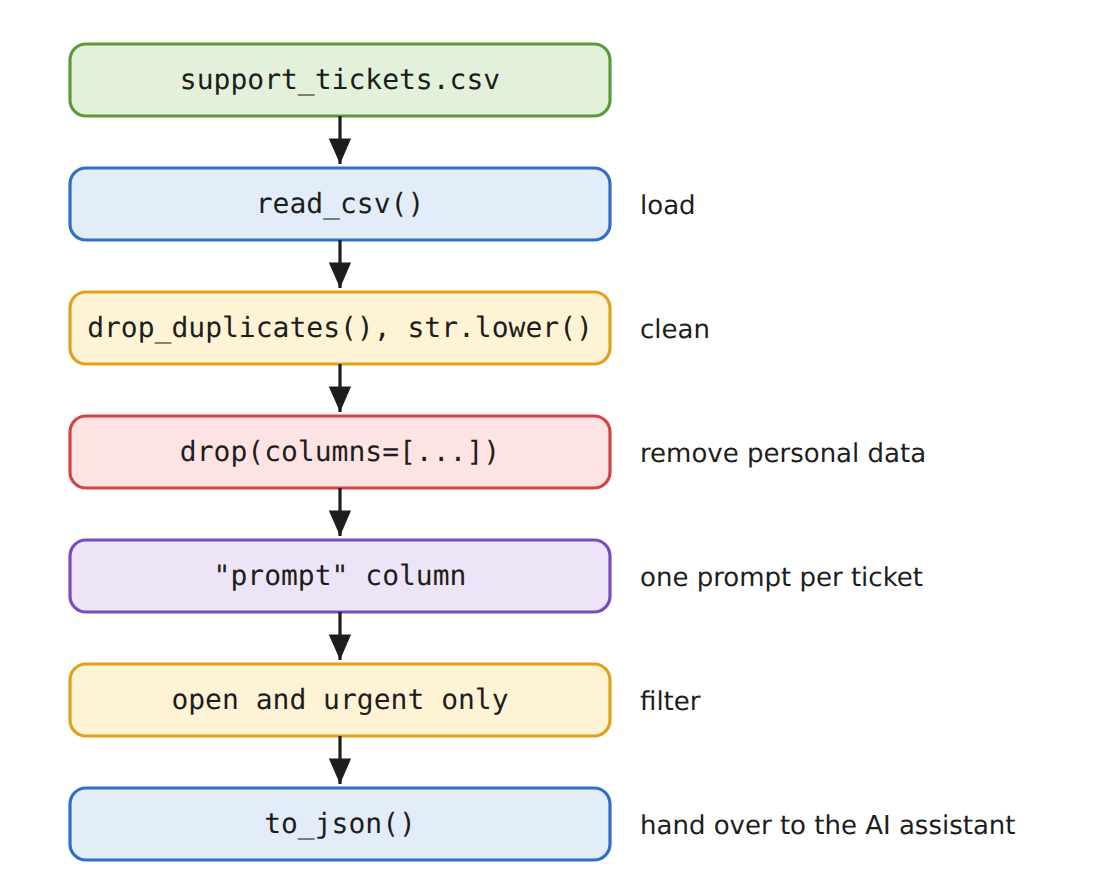

### Step 1 — Load, clean, and remove personal data

The same steps as Section 4, one after the other.

In [ ]:
batch = pd.read_csv(CSV_PATH)
batch = batch.drop_duplicates()
batch["Ticket Type"] = batch["Ticket Type"].str.lower()
batch["Ticket Subject"] = batch["Ticket Subject"].fillna("Unknown subject")
batch = batch.drop(columns=["Notes", "Customer Name", "Customer Email"])
print(batch.shape)

### Step 2 — One prompt per ticket, then only the open, urgent tickets

Open means not closed. Urgent means a priority of Critical or High.

In [ ]:
batch["prompt"] = (
    "Product: " + batch["Product Purchased"]
    + " | Type: " + batch["Ticket Type"]
    + " | Subject: " + batch["Ticket Subject"]
)

batch = batch[(batch["Ticket Status"] != "Closed") & (batch["Ticket Priority"].isin(["Critical", "High"]))]
print(len(batch), "tickets for the assistant")

for prompt in batch["prompt"].head(3):
    print(prompt)

### Step 3 — Save it for the assistant

In [ ]:
batch[["Ticket ID", "Ticket Priority", "prompt"]].to_json("ai_batch.json", orient="records", indent=2)
print("Saved ai_batch.json")

---

### 🎉 That's Class 3!

| Concept | Key syntax |
|---------|------------|
| Bring in pandas | `import pandas as pd` |
| Read a file | `pd.read_csv(CSV_PATH)` |
| Size, first rows, names | `.shape`, `.head()`, `.columns` |
| Types and missing | `.info()` |
| One column (a Series) | `tickets["Ticket Type"]` |
| Several columns | `tickets[["a", "b"]]` |
| Filter rows | `tickets[tickets["Ticket Priority"] == "Critical"]` |
| Combine conditions | `(A) & (B)`, `(A) \| (B)` |
| Value in a list | `.isin(["Email", "Chat"])` |
| Count missing | `.isnull().sum()` |
| Remove duplicates | `.drop_duplicates()` |
| Tidy text | `.str.lower()`, `sorted(... .unique())` |
| Fill / drop missing | `.fillna(...)`, `.dropna(subset=[...])` |
| Remove columns | `.drop(columns=[...])` |
| New column | `tickets["new"] = ...` |
| Statistics | `.mean()`, `.min()`, `.max()`, `.sum()`, `.round(1)` |
| Values in a column | `.nunique()`, `.value_counts()` |
| Per group | `.groupby("col")["other"].mean()` |
| Per group of two columns | `.groupby(["col1", "col2"])["other"].mean()` |
| Several statistics | `.agg(["mean", "min", "max", "count"])` |
| Sort a result | `.sort_values(ascending=False)` |
| Save | `.to_csv(..., index=False)`, `.to_json(..., orient="records")` |

> ⚠️ The one to remember: these methods give back a **new** table. `tickets.drop_duplicates()` on its own changes nothing — write `tickets = tickets.drop_duplicates()`.

> 🤖 **The big picture:** You just prepared the input of a real AI feature: clean, private, one prompt per ticket, saved as a list of dictionaries in JSON. In Class 4 you will wrap these steps in **functions**, so the whole pipeline runs again with one line.

➡️ Now open the **exercises notebook**.